# 04: Comparing models by cross-validation

Notebook 03 chose XGBoost's settings on 27 validation storms, and that turned out to be too few.
On storms held back from the choice, its lead over CLIPER fell to 0% at +48 h and about 3% at
+72 h. This notebook replaces that single split with cross-validation, then uses it to compare
five models fairly, and applies the rule in `CLAUDE.md` that picks the primary model.

All the logic lives in `src/cyclone/`, and `docs/components.md` explains each module. This
notebook only calls it in order: load → check the blocks → search → forecast → score → decide.

**Only the development seasons, 1980–2017, are used. The test split stays locked.** No forecast is
made for a test storm here, and the final model isn't scored. Test is scored once, at the end of
Project 1.

**Running locally:** use the `cyclone` kernel after `pip install -e .`. Run notebook 01 first,
because this one reads `ni_clean.parquet`. It takes about 2 minutes on a laptop CPU with the search
results already saved, and about 10 minutes more on a fresh machine, which has to run the search.

**Running on Colab:** run these in a first cell:

```python
!git clone https://github.com/Anshuman-Alok-Gupta/Cyclone_Project.git
!pip install -e Cyclone_Project
```

Then choose *Runtime → Restart session*, because Python only finds a newly installed
editable package when it starts. After the restart, run this before the cells below:

```python
from google.colab import drive
drive.mount("/content/drive")

import os
os.environ["CYCLONE_DATA_DIR"] = "/content/drive/MyDrive/cyclone-project/data"
```

In [1]:
import pandas as pd

from cyclone import config, cv, final_model, xgb_model
from cyclone.baselines import cliper_forecast, persistence_forecast
from cyclone.checks import check_expected, check_folds, check_samples
from cyclone.consensus import CONSENSUS_NAME, consensus
from cyclone.features import build_features
from cyclone.plotting import plot_storm_gaps
from cyclone.samples import make_init_times, make_truth
from cyclone.scoring import score, summarize

## What cross-validation does

The development seasons are cut into five blocks of whole, consecutive seasons: 1980–87, 1988–95,
1996–2003, 2004–10 and 2011–17. Then, five times over:

1. Hold one block out.
2. Fit a model on the other four.
3. Forecast the block it never saw.

Putting the five sets of forecasts together gives **out-of-fold forecasts**. Every development
start time has exactly one, from a model that never saw that storm. So a comparison now rests on
all 211 storms, not on the 27 that happened to fall in one split.

## Load, and check the blocks

`check_folds` compares the storm, start-time and case counts in each block with verified numbers,
and stops the run if a storm is in two blocks or a test season is in any block. It runs on the
feature table, so a row dropped while building the inputs would stop it too.

`cv.model_rows` then joins everything any model reads into one table, for development storms only.
Test storms are left out at this point, so they never enter the cross-validation at all.

In [2]:
df = pd.read_parquet(config.ni_clean_path())
check_expected(df)

truth = make_truth(df)
init_times = make_init_times(df)
check_samples(init_times, truth)

features = build_features(init_times)
check_folds(df, features, truth)

rows = cv.model_rows(init_times, features, df)
print(f"\n{len(rows):,} development start times in {rows['fold'].nunique()} blocks")
print(f"Latest block: {rows['fold'].max()}")

Counts match: 5,694 rows, 258 storms, 184/27/47 train/val/test.
Sample counts match: 4,678 init times.
  train 3,203 init times; cases +24 h 2,515, +48 h 1,869, +72 h 1,324
  val     542 init times; cases +24 h 438, +48 h 340, +72 h 256
  test    933 init times; cases +24 h 749, +48 h 578, +72 h 430


Fold counts match: 211 storms, 3,745 init times.
  1980-1987   39 storms,  598 init times; cases +24 h 452, +48 h 324, +72 h 218
  1988-1995   44 storms,  774 init times; cases +24 h 617, +48 h 465, +72 h 325
  1996-2003   48 storms,  952 init times; cases +24 h 774, +48 h 605, +72 h 463
  2004-2010   43 storms,  737 init times; cases +24 h 570, +48 h 413, +72 h 284
  2011-2017   37 storms,  684 init times; cases +24 h 540, +48 h 402, +72 h 290

3,745 development start times in 5 blocks
Latest block: 2011-2017


## Search for XGBoost's settings

**Why the number of trees is now a searched setting.** In notebook 03, each model kept adding trees
until its error on the validation storms stopped improving. That's *early stopping*, and it can't
be used here. To decide when to stop, it has to watch some storms, and in a fold the only storms
left over are the held-out block. If those chose the tree count, the block's own answers would have
shaped the forecast being scored, which is the leak cross-validation exists to remove.

This isn't only theory. A one-off test did exactly that with one seed, and XGBoost's skill rose from
6.0, 3.3 and 0.7% to 6.6, 4.1 and 1.5%. A gain that comes from letting a block choose its own stopping point can't
be trusted.

So each fold keeps every tree it's given, and the number of trees is searched along with the other
settings. Holding back some of the learning blocks to stop on would cost training storms, and would
leave each fold with a different count and no single setting to use at the end.

**How a combination is judged.** Each of 20 combinations runs through all five folds, and is scored
on the mean error over every out-of-fold case. The rule is the same as before: each lead's error is
divided by the best any combination reached there, so that 72 h's larger errors don't decide
everything. The random seed is fixed.

**`xgb_residual` gets its own search,** with the same 20 combinations. It predicts CLIPER's error,
which is a much smaller target than the storm's movement, so borrowing plain XGBoost's settings
would handicap it.

**The search isn't run again here.** It ran once, on seed 42, and took about 5 minutes per model on
a CPU. Its results were written to the data directory after every combination, and `RESUME = True`
reads all 20 back and fits nothing. So the tables below are that search, and on a fresh machine, where
nothing is saved, it runs in full. If the data or the inputs ever change, set `RESUME = False`, or the
old results will be reused without warning.

In [3]:
RESUME = True

device = xgb_model.pick_device()
checkpoints = config.xgboost_final_dir()

xgboost_search = xgb_model.search_cv(
    rows, truth, device=device, checkpoint=checkpoints / "search_xgboost.csv", resume=RESUME
)
xgboost_search.head(8).round(3)

Searching 20 combinations on cpu, 5 folds each
  Resuming: 20 combinations already done


,subsample,n_estimators,min_child_weight,max_depth,learning_rate,km_24h,km_48h,km_72h,relative_error
0,0.6,200,5,3,0.02,136.670,316.570,494.420,1.000
1,0.8,100,40,3,0.05,136.582,317.522,494.854,1.001
2,0.8,100,5,3,0.05,136.643,318.146,498.339,1.004
3,0.8,200,10,2,0.05,137.004,317.410,498.903,1.005
4,0.8,100,5,4,0.05,138.022,322.867,502.139,1.015
5,1.0,50,5,3,0.05,139.745,323.923,503.400,1.022
6,0.6,100,10,3,0.02,141.867,325.282,502.384,1.027
7,0.6,200,5,6,0.02,140.081,327.961,512.698,1.033


In [4]:
residual_search = xgb_model.search_cv(
    rows,
    truth,
    xgb_model.residual_forecaster,
    device=device,
    checkpoint=checkpoints / "search_residual.csv",
    resume=RESUME,
)
residual_search.head(8).round(3)

Searching 20 combinations on cpu, 5 folds each
  Resuming: 20 combinations already done


,subsample,n_estimators,min_child_weight,max_depth,learning_rate,km_24h,km_48h,km_72h,relative_error
0,0.6,100,10,3,0.02,142.634,323.087,489.175,1.002
1,0.6,200,5,3,0.02,142.095,323.312,490.775,1.003
2,0.8,50,5,5,0.02,142.787,322.634,491.279,1.004
3,0.6,100,40,2,0.02,143.249,322.934,490.917,1.005
4,1.0,50,40,3,0.02,143.869,323.063,492.113,1.007
5,1.0,100,10,3,0.02,143.779,324.737,490.040,1.007
6,0.8,100,5,3,0.05,141.809,324.534,498.720,1.009
7,0.8,100,40,3,0.05,141.784,324.864,498.531,1.009


Both tables are sorted best first, and the top few combinations in each are very close, so the
choice isn't critical. Both winners are cautious: shallow trees, the slowest learning rate, and a
small share of rows per tree. Notebook 03 pointed the same way, and it's what you'd expect when
most of what's left to learn is noise. `xgb_residual`'s winner is the more cautious of the two,
because there's less left to find once CLIPER has taken the straight-line part.

In [5]:
xgboost_settings = xgb_model.best_settings(xgboost_search)
residual_settings = xgb_model.best_settings(residual_search)
print("XGBoost:     ", xgboost_settings)
print("xgb_residual:", residual_settings)

XGBoost:      {'max_depth': 3, 'learning_rate': 0.02, 'min_child_weight': 5, 'subsample': 0.6, 'n_estimators': 200}
xgb_residual: {'max_depth': 3, 'learning_rate': 0.02, 'min_child_weight': 10, 'subsample': 0.6, 'n_estimators': 100}


## Forecast with all five models

Every model takes the same route through `cv.out_of_fold`, so each fold's model sees only that fold's
learning blocks:

- **Persistence** has nothing to fit.
- **CLIPER** is refitted in each fold.
- **XGBoost** uses the settings found above, and averages 5 seeds.
- **`xgb_residual`** fits CLIPER inside each fold, on the learning blocks only, then fits XGBoost to
  CLIPER's errors and adds its correction to CLIPER's forecast. It averages 5 seeds too.
- **Consensus** is the average of the CLIPER and XGBoost positions for each case. Each member is
  already out of fold, so the average is too. It has nothing to fit: if one forecast is too far north
  and the other too far south, the point between them is closer than either. Its XGBoost member is
  the 5-seed average.

**Why 5 seeds.** Training has a random part: `subsample` gives each tree a random share of the rows.
So one seed's forecast is partly luck, and the same model scores slightly differently from seed to
seed. A forecast here is the average of the positions from seeds 42 to 46. Averaging leaves no room
to pick a kind seed, and the final model does the same, so the model measured is the model that goes
to test. The single-seed forecasts are made as well, to show what the average changed.

**How the runner stops leaks.** The held-out block's storms are removed from the truth table before
a model receives it, so it can't learn from those answers whatever its code does. On this data,
moving every truth position in one block left that block's forecasts identical for CLIPER, XGBoost
and `xgb_residual`, while every forecast in the other four blocks moved. Corrupting every test row
changed nothing at all. The tests in `tests/test_cv.py` do the same on every run.

In [6]:
references = pd.concat(
    [
        cv.out_of_fold(rows, truth, persistence_forecast),
        cv.out_of_fold(rows, truth, cliper_forecast),
    ],
    ignore_index=True,
)


def five_models(seeds):
    members = pd.concat(
        [
            references,
            cv.out_of_fold(rows, truth, xgb_model.xgboost_forecaster(xgboost_settings, device, seeds)),
            cv.out_of_fold(rows, truth, xgb_model.residual_forecaster(residual_settings, device, seeds)),
        ],
        ignore_index=True,
    )
    return pd.concat([members, consensus(members, members=("cliper", "xgboost"))], ignore_index=True)


scored = score(five_models(xgb_model.SEEDS), truth)
summary = summarize(scored, homogeneous=True)
single_seed_scored = score(five_models((xgb_model.SEED,)), truth, report=False)

cliper: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
consensus: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
persistence: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
xgb_residual: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
xgboost: scored 6,742 of 11,235 forecasts; 4,493 had no matching truth
Homogeneous comparison: kept 33,710 of 33,710 scored forecasts, the cases all 5 models have.


## Score all five, on identical cases

The summary above confirms all five models have every case. Each lead's count below must be the total
verified by `check_folds`: 2,953, 2,209 and 1,580. Every number from here on is for the 5-seed models,
unless it says otherwise.

**Skill** is the percentage improvement in mean error over CLIPER. **The 95% interval** comes from a
bootstrap: redraw the storms at random 10,000 times, work out the skill each time, and keep the middle
95%. It shows how far the skill could move if the storms had been a different draw.

**The bootstrap redraws whole storms, not rows.** Forecasts from one storm, six hours apart, are nearly
the same forecast of nearly the same situation, so 20 of them are much closer to 1 piece of evidence
than to 20. Redrawing rows would count them as 20. A one-off test shows the difference: consensus at
+72 h has an interval of 0.5 to 4.2% by storm, but 1.6 to 3.2% by row, which looks far more certain
than the data allows.

**Win rate** is the share of cases where a model is closer than CLIPER. CLIPER has no interval or win
rate against itself.

In [7]:
MODEL_ORDER = ["persistence", "cliper", "xgboost", "xgb_residual", CONSENSUS_NAME]

intervals = cv.bootstrap_skill(scored)
wins = cv.win_rate(scored).stack().rename("win_rate_%").reset_index()

results = (
    summary.merge(intervals[["model", "lead_h", "skill", "low", "high"]], how="left", on=["model", "lead_h"])
    .merge(wins, how="left", on=["model", "lead_h"])
    .assign(model=lambda table: pd.Categorical(table["model"], MODEL_ORDER, ordered=True))
    .sort_values(["lead_h", "model"])
    .set_index(["lead_h", "model"])
)
results.round(1)

count  mean_km  median_km  skill   low  high  win_rate_%
lead_h model                                                                 
24     persistence    2953    155.6      135.0   -7.1  -9.4  -4.8        45.1
       cliper         2953    145.3      127.6    NaN   NaN   NaN         NaN
       xgboost        2953    136.5      120.1    6.1   4.6   7.6        59.0
       xgb_residual   2953    142.6      125.5    1.9   1.0   2.8        56.6
       consensus      2953    138.2      121.6    4.9   4.2   5.7        63.3
48     persistence    2209    367.7      329.1  -12.3 -16.8  -7.9        41.3
       cliper         2209    327.3      298.6    NaN   NaN   NaN         NaN
       xgboost        2209    316.5      284.2    3.3   0.7   5.7        54.1
       xgb_residual   2209    322.6      289.8    1.4  -0.4   3.1        53.0
       consensus      2209    316.3      283.5    3.4   2.2   4.5        58.0
72     persistence    1580    601.7      544.9  -20.9 -28.2 -13.8        36.4
       cliper         1580    497.9      445.4    NaN   NaN   NaN         NaN
       xgboost        1580    494.2      447.5    0.7  -3.4   4.5        48.4
       xgb_residual   1580    489.6      440.3    1.6  -0.9   3.9        52.0
       consensus      1580    486.0      435.2    2.4   0.5   4.2        53.2

Two things stand out.

**The validation storms were easy.** CLIPER's mean error here is 145, 327 and 498 km. On the 2013–17
storms in notebook 03 it was 129, 289 and 459 km. Any score from those seasons alone was flattered by
that, for every model.

**XGBoost's lead at +72 h has gone.** It was 8.0% in notebook 03, and here it's 0.7%, with an interval
either side of zero.

## What averaging 5 seeds changed

Here's each candidate's skill and interval with one seed and with five, side by side.

In [8]:
CANDIDATES = ["xgboost", CONSENSUS_NAME, "xgb_residual"]

by_seeds = pd.concat(
    {"1 seed": cv.bootstrap_skill(single_seed_scored), "5 seeds": cv.bootstrap_skill(scored)},
    names=["seeds"],
).reset_index(level="seeds")
by_seeds = by_seeds[by_seeds["model"].isin(CANDIDATES)]
by_seeds.pivot(index=["model", "lead_h"], columns="seeds", values=["skill", "low", "high"]).round(1)

skill            low           high        
seeds               1 seed 5 seeds 1 seed 5 seeds 1 seed 5 seeds
model        lead_h                                             
consensus    24        4.9     4.9    4.1     4.2    5.7     5.7
             48        3.4     3.4    2.2     2.2    4.5     4.5
             72        2.4     2.4    0.4     0.5    4.3     4.2
xgb_residual 24        1.9     1.9    0.9     1.0    2.8     2.8
             48        1.3     1.4   -0.6    -0.4    3.0     3.1
             72        1.7     1.6   -0.8    -0.9    4.0     3.9
xgboost      24        6.0     6.1    4.4     4.6    7.5     7.6
             48        3.3     3.3    0.7     0.7    5.7     5.7
             72        0.7     0.7   -3.5    -3.4    4.5     4.5

Very little. No skill moved by more than 0.15 of a point, and the intervals are about as wide as before. That's
what you'd expect: the interval measures the luck of which storms occurred, and averaging seeds does
nothing about that. It removes a much smaller doubt, which is how much of a score belongs to one seed.

A separate one-off shows how small that doubt was. Seeds 42 to 46 on their own gave consensus 2.2 to 2.4%
at +72 h, and a second set of five seeds, 47 to 51, averaged 2.3%, against 2.4% here.

## Skill block by block

An overall number can hide a model that wins on the strength of one block.

In [9]:
by_fold = cv.skill_by_fold(scored)[CANDIDATES]
by_fold.round(1)

model             xgboost  consensus  xgb_residual
lead_h fold                                       
24     1980-1987      6.5        4.8           2.2
       1988-1995      7.0        5.2           3.1
       1996-2003      5.5        5.0           0.8
       2004-2010      6.5        4.9           2.4
       2011-2017      5.1        4.8           1.1
48     1980-1987      5.9        4.1           1.8
       1988-1995      2.9        2.9           2.2
       1996-2003      1.9        3.3           0.7
       2004-2010      4.8        4.1           1.9
       2011-2017      1.5        2.4           0.6
72     1980-1987      4.2        3.7           3.5
       1988-1995     -3.4       -0.2           0.6
       1996-2003     -1.5        2.5           0.4
       2004-2010      4.5        4.0           4.7
       2011-2017      1.7        2.2          -0.3

At +24 h, XGBoost and consensus beat CLIPER by a similar amount in all five blocks, and at +48 h both
are ahead in all five, which is about as steady as a result gets. At +72 h, XGBoost is behind CLIPER
in two blocks and ahead in three, so its overall number is close to zero for good reason. Consensus is
ahead in four blocks and level in the fifth.

## Is one model better than the other?

Skill against CLIPER doesn't say whether consensus is better than XGBoost. Comparing them directly, on
the same redraws, does. The rows below are each model's skill against XGBoost.

In [10]:
against_xgboost = cv.bootstrap_skill(scored, reference="xgboost")
against_xgboost[against_xgboost["model"] == CONSENSUS_NAME].round(1)

,model,lead_h,skill,low,high,storms,cases
1,consensus,24,-1.2,-2.2,-0.3,194,2953
5,consensus,48,0.1,-1.4,1.6,171,2209
9,consensus,72,1.6,-0.5,3.9,140,1580


XGBoost alone is slightly better at +24 h, the two are level at +48 h, and consensus leads at +72 h
with an interval that crosses zero. So it's not a clean win for either. They trade places, and
consensus gives up very little at short range for a steadier +72 h.

## Which model is primary?

The test plan in `CLAUDE.md` fixes the rule, so nothing here is a judgement call. A candidate's score is
its mean skill against CLIPER across +24, +48 and +72 h, each lead counting equally, and the highest
score is the primary model. Persistence and CLIPER are references, so they aren't in the race.

The interval is for information only, and it doesn't affect the choice. One redraw of the storms covers
all three leads at once here, because a storm that's kind to a model at +24 h is the same storm at +72 h.

In [11]:
pd.concat(
    {
        "1 seed": cv.selection_scores(single_seed_scored, CANDIDATES).set_index("model"),
        "5 seeds": cv.selection_scores(scored, CANDIDATES).set_index("model"),
    },
    axis=1,
).round(2)

1 seed             5 seeds            
              score   low  high   score   low  high
model                                              
consensus      3.55  2.48  4.59    3.56  2.48  4.62
xgboost        3.31  0.92  5.54    3.38  0.96  5.62
xgb_residual   1.63  0.02  3.08    1.66  0.06  3.09

Consensus leads with 3.56 against XGBoost's 3.38, so it's the primary model today. That gap of 0.18 is
much smaller than either interval, and the rule picks the higher score anyway. That's deliberate: the
alternative is a judgement about what counts as close, and both models get their own test interval either
way. The gap did hold up. Consensus came first with each of seeds 42 to 46 alone, and with seeds 47 to 51
averaged.

## The primary model, storm by storm at +72 h

Each bar below is one storm: the model's mean error minus CLIPER's, at +72 h. Below zero means the
model did better. The bars are sorted, so the shape shows whether a lead comes from most storms or a
few big ones.

Primary model: consensus


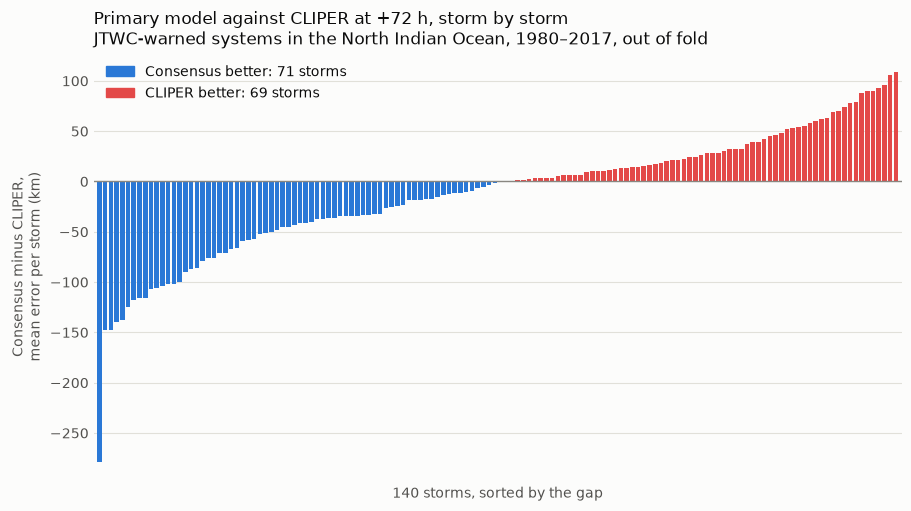

In [12]:
best = cv.selection_scores(scored, CANDIDATES)["model"].iloc[0]
print(f"Primary model: {best}")

gaps = cv.storm_gaps(scored, best)
plot_storm_gaps(
    gaps,
    model=best,
    title="Primary model against CLIPER at +72 h, storm by storm\n"
    "JTWC-warned systems in the North Indian Ocean, 1980–2017, out of fold",
);

In [13]:
names = df.drop_duplicates("SID").set_index("SID")[["NAME", "SEASON"]]
print("Its largest wins and losses:")
display(pd.concat([gaps.head(3), gaps.tail(3)]).join(names).round(1))

steady = gaps[gaps["cases"] >= 5]
print(f"All {len(gaps)} storms: better on {(gaps['gap_km'] < 0).sum()}")
print(f"The {len(steady)} storms with at least 5 cases: better on {(steady['gap_km'] < 0).sum()}")

Its largest wins and losses:


,model_km,reference_km,gap_km,cases,NAME,SEASON
SID,,,,,,
2009104N13088,556.8,835.3,-278.5,1,BIJLI,2009
1980338N09085,739.3,887.3,-148.0,3,UNNAMED,1980
2015280N13071,208.2,355.4,-147.3,2,UNNAMED,2015
2012321N14090,448.4,352.9,95.6,14,UNNAMED,2012
1996167N16072,388.4,282.6,105.8,27,UNNAMED,1996
1994157N17074,511.0,402.4,108.7,2,UNNAMED,1994


All 140 storms: better on 71
The 109 storms with at least 5 cases: better on 57


Storm by storm, it's even: consensus is better on 71 of 140 storms and CLIPER on 69, and it's 57 to 52
on the 109 storms with at least 5 cases. Consensus's lead comes from its wins being larger than its
losses: 57 km on average against 35 km, which is the long blue tail on the left of the chart.

The bars aren't equally reliable. The longest, Bijli in 2009, rests on a single +72 h forecast, while
others average dozens.

## How far to trust these numbers

The interval covers the luck of which storms occurred. It leaves out some other things, so each was
tested separately. All of these are one-off tests, recorded in `docs/components.md`.

**Choosing settings on the same forecasts.** The settings were picked on these out-of-fold forecasts,
which is the problem notebook 03 had, on a much smaller scale. *Nested* cross-validation measures it:
for each block, the settings are picked using only the other four, so the block played no part in the
choice. These runs use 5 seeds, with each block's settings as picked in an earlier one-seed run. This is
the fair version, and it barely moves:

| Skill vs CLIPER | +24 h | +48 h | +72 h | Score |
|---|---:|---:|---:|---:|
| XGBoost, this notebook | 6.1% | 3.3% | 0.7% | 3.38 |
| XGBoost, nested | 6.1% | 3.2% | 0.3% | 3.18 |
| Consensus, this notebook | 4.9% | 3.4% | 2.4% | 3.56 |
| Consensus, nested | 5.0% | 3.3% | 2.2% | 3.50 |
| `xgb_residual`, this notebook | 1.9% | 1.4% | 1.6% | 1.66 |
| `xgb_residual`, nested | 1.6% | 1.2% | 0.9% | 1.23 |

In notebook 03, the same kind of test took XGBoost's +48 h skill from 4.7% to 0.0%. Here it costs
XGBoost 0.5 at most, consensus 0.2, and `xgb_residual` 0.8, so cross-validation has done what it was
brought in to do, and the order of the three scores doesn't change. The settings were steady too: in
the nested runs, XGBoost always chose depth 3, and only two combinations ever won.

**Looking at many numbers at once.** A 95% interval is fair for one number chosen in advance. Here
the eye goes to the best of three models at three leads, which is nine looks. Allowing for that widens
the intervals (a Bonferroni correction, 99.4%):

| Skill vs CLIPER, allowing for nine looks | +24 h | +48 h | +72 h |
|---|---:|---:|---:|
| XGBoost | 3.9 to 8.3% | −0.4 to 6.7% | −5.3 to 5.9% |
| Consensus | 3.8 to 6.0% | 1.7 to 4.9% | **−0.4 to 5.0%** |
| `xgb_residual` | 0.6 to 3.2% | −1.3 to 3.8% | −2.1 to 4.7% |

**Storms in one season being alike.** Redrawing whole seasons instead of storms gave intervals no wider
(consensus at +72 h: 0.9 to 3.8%), so this isn't making the intervals too narrow.

**One choice made with one seed.** The settings were searched on seed 42 and aren't searched again, so
they're the best of 20 for that seed, then measured with five. The top combinations were very close, and
the nested runs above show how little the choice matters.

## Conclusion

**Under the test plan's rule, the primary model today is the consensus of CLIPER and XGBoost, narrowly
ahead of XGBoost alone.** Their scores are 3.56 and 3.38. Consensus's mean error is 138, 316 and 486 km,
against CLIPER's 145, 327 and 498 km. That's 7, 11 and 12 km closer.

| Lead time | Does a model clearly beat CLIPER? |
|---|---|
| +24 h | **Yes.** Consensus (4.9%) and XGBoost (6.1%) both do, in every block, and it holds up under every test above. XGBoost alone is slightly the better of the two here. |
| +48 h | **Yes, for consensus** (3.4%): it's ahead in every block, and stays clear after allowing for nine looks. XGBoost has nearly the same mean error, but a wider interval that no longer clears zero once the nine looks are allowed for. |
| +72 h | **No.** Consensus is ahead by 2.4%, or 12 km, but that's not clearly bigger than the uncertainty. Its 95% interval only just clears zero (0.5 to 4.2%), that stops being true after allowing for nine looks, and storm by storm it's 71 to 69. XGBoost alone (0.7%) shows no lead at all. |

`xgb_residual` is ahead of CLIPER by a small amount at each lead, and is clearly so only at +24 h. It
beats plain XGBoost at +72 h, but it's behind consensus at every lead, so consensus does its job better.

Three days out, these models can't reliably beat a straight-line fit. That fits what they can see: only
a storm's own past, which says less and less as the range grows. What steers a storm over three days
is the wind around it, which none of them knows about, and which the AI weather models in Project 3
work from.

**Scope.** These results are for JTWC-warned systems in the North Indian Ocean, 1980–2017. They were
measured across seasons in both directions, so a model can learn from later seasons than it forecasts,
which a real forecast couldn't. The test split is the fair check on that: all its seasons come last.

## Fit the final consensus

For the end of Project 1, CLIPER and all 5 seeds of XGBoost are refitted on all of 1980–2017, and saved.
Cross-validation's models each saw four blocks, and their job was to measure a model. Once it's measured,
using all five gives the final one more storms to learn from.

It isn't scored here. It has seen every one of these storms, so a score would mean nothing, and the
cross-validated numbers above stand in for it. Test is scored once, after the LSTM and West Pacific
pretraining steps. Those steps may change which model is primary, so this is today's leader, not a final
decision.

Reloading must give exactly the same forecasts. The check below uses development storms, since this
notebook makes no test forecast.

In [14]:
final = final_model.fit_final_consensus(rows, truth, xgboost_settings, device)
final_model.save_final_consensus(final, xgboost_search)

reloaded = final_model.load_final_consensus()
same_forecasts = final_model.final_consensus_forecast(final, rows).equals(
    final_model.final_consensus_forecast(reloaded, rows)
)
print(f"Seeds fitted: {list(final.xgboost)}")
print(f"Reloaded models give identical forecasts: {same_forecasts}")

Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed42
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed43


Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed44
Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed45


Saved 6 models to D:\Cyclone_proj\data\models\xgboost_final\seed46


Seeds fitted: [42, 43, 44, 45, 46]
Reloaded models give identical forecasts: True
